# 04 · Modelos de painel e interpretação

Este notebook completa as secções 3.2 e 3.3 do guião. Compara pooled OLS, efeitos fixos e aleatórios, avalia os resíduos e responde à questão sobre clima e inflação alimentar. A especificação principal usa agricultura como moderadora; o log PIB permanece na exploração.

**Leitura principal:** a associação contemporânea ao peso agrícola médio não exclui zero quando se controla a sazonalidade nacional. A versão com temperatura desfasada um mês apresenta uma associação positiva. O momento da exposição importa, e os dois resultados devem ser lidos em conjunto.

As escolhas e limites administrativos estão em `docs/decisoes_parte1.md`. A análise é retrospetiva até dezembro de 2025 e não seleciona qualquer SARIMA.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Markdown, Image

raiz = Path.cwd() if (Path.cwd() / "scripts").is_dir() else Path.cwd().parent
if str(raiz / "scripts") not in sys.path:
    sys.path.insert(0, str(raiz / "scripts"))
from preparacao import ler_painel
from modelos_painel import executar, TERMOS
from graficos_parte1 import executar as criar_graficos
from sintese_parte1 import gerar, tabela_modelos, numero
from auditoria import executar as auditar

dados = ler_painel(raiz / "dados/originais")
tabelas = raiz / "resultados/tabelas/04_modelos"
graficos = raiz / "resultados/graficos/04_modelos"
coefs, residuos_pais, resumo_residuos, metadados = executar(dados, tabelas)
assert coefs.n.eq(len(dados)).all()
assert coefs.grupos.eq(15).all()
criar_graficos(dados, tabelas, graficos)
inferencia_dk, influencia, auditoria = auditar(dados, tabelas)
texto = gerar(raiz)
print(f"{len(dados)} observações; 15 países; cinco modelos e três verificações de sensibilidade.")

4665 observações; 15 países; cinco modelos e três verificações de sensibilidade.


## 1. O que cada modelo identifica

Definimos $A^c=A-\bar A$ e estimamos

$$y_{it}=\beta_0+\beta_1 T_{it}+\beta_2 D_{it}+\beta_3 A^c_{i,t-1}
+\beta_4 T_{it}A^c_{i,t-1}+\alpha_i+\lambda_t+\gamma_{i,m(t)}+\varepsilon_{it}.$$

O pooled omite os efeitos de país; o FE estima interceptos nacionais; o RE trata esses interceptos como aleatórios e exige ausência de correlação com todas as covariáveis. O trio inicial não inclui efeitos de tempo. As duas extensões FE acrescentam efeitos de data e de país × mês, sempre com os mesmos quatro termos e 4 665 observações.

No FE, a associação vem das mudanças dentro do mesmo país. Com efeitos de data, retiram-se também os choques comuns. Uma variável constante no país seria absorvida. A agricultura não é constante, mas apenas 2,81% da sua variabilidade ocorre dentro dos países; não se deve interpretar o coeficiente próprio como efeito causal. Mantê-lo respeita a hierarquia da interação.

No RE, a condição $E(\alpha_i\mid X_i)=0$ é forte: estrutura alimentar, instituições e integração comercial podem relacionar-se com os regressores. O FE permite essa correlação, mas não elimina endogeneidade nos erros que variam no tempo.

In [2]:
display(Markdown(f"O centro da agricultura é **{metadados['centro_agricultura']:.3f}% do PIB**. "
                 f"No RE, θ = **{metadados['theta_re']:.3f}**. "
                 "As previsões antes e depois da centragem coincidem; o FE foi também conferido pelo cálculo within."))

O centro da agricultura é **15.436% do PIB**. No RE, θ = **0.664**. As previsões antes e depois da centragem coincidem; o FE foi também conferido pelo cálculo within.

## 2. Trio de referência: mesma amostra e covariáveis

**Tabela 4.1.** Coeficientes e IC 95%, com erros agrupados por país, correção finita e distribuição t(14). Os CSV incluem ainda erros padrão e valores-p. Há apenas 15 grupos: a inferência é aproximada.

O R² OLS do pooled e FE inclui os efeitos estimados; o R² RE é da regressão transformada por GLS. Não são usados como uma escala comum para escolher o estimador.

In [3]:
display(Markdown(tabela_modelos(coefs, ["Pooled", "FE pais", "RE"])))

| Termo | Pooled | FE pais | RE |
|---|---|---|---|
| Anomalia térmica | -0,060 [-0,117; -0,003] | -0,049 [-0,109; 0,011] | -0,051 [-0,110; 0,007] |
| Défice hídrico | -0,028 [-0,107; 0,050] | -0,025 [-0,104; 0,055] | -0,026 [-0,105; 0,052] |
| Peso agrícola centrado | 0,005 [-0,007; 0,017] | -0,032 [-0,073; 0,009] | -0,002 [-0,014; 0,010] |
| Anomalia × peso agrícola | -0,001 [-0,004; 0,001] | -0,001 [-0,003; 0,002] | -0,001 [-0,003; 0,001] |
| Observações | 4665 | 4665 | 4665 |
| R² do modelo | 0,0021 | 0,0272 | 0,0008 |

O coeficiente térmico mantém o sinal negativo no FE país, mas o intervalo passa a incluir zero. O coeficiente próprio da agricultura muda de sinal. A comparação mostra por que motivo diferenças entre países não devem ser lidas como mudanças dentro do mesmo país.

## 3. Choques comuns e sazonalidade nacional

**Tabela 4.2.** Extensões de efeitos fixos. O efeito de cada data controla choques comuns; os contrastes país × mês permitem calendários sazonais diferentes. Como os meses comuns já estão contidos nos efeitos de data, usam-se 14 × 11 = 154 contrastes sazonais adicionais, evitando colinearidade.

| Termo | FE pais e data | FE pais data sazonal |
|---|---|---|
| Anomalia térmica | -0,058 [-0,109; -0,007] | -0,044 [-0,097; 0,008] |
| Défice hídrico | -0,022 [-0,092; 0,049] | -0,022 [-0,081; 0,037] |
| Peso agrícola centrado | -0,031 [-0,065; 0,003] | -0,031 [-0,066; 0,004] |
| Anomalia × peso agrícola | 0,002 [-0,002; 0,007] | 0,002 [-0,004; 0,008] |
| Observações | 4665 | 4665 |
| R² do modelo | 0,1464 | 0,3805 |

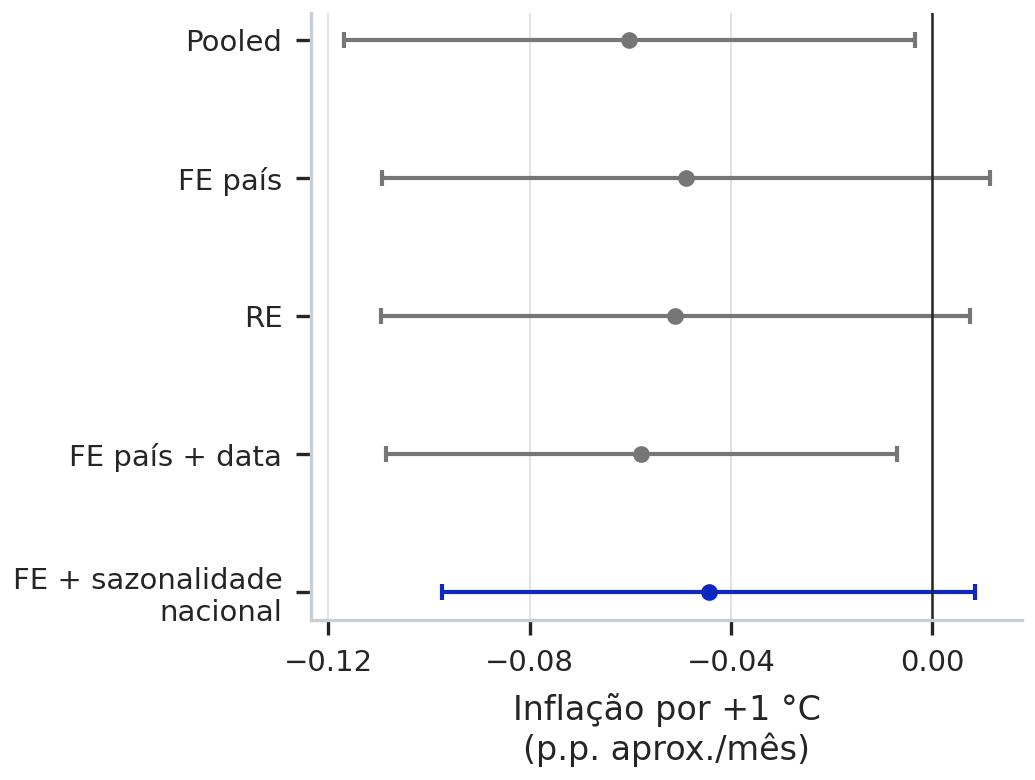

In [4]:
display(Markdown(tabela_modelos(coefs, ["FE pais e data", "FE pais data sazonal"])))
display(Image(filename=str(graficos / "03_calor_modelos.png"), width=550))

**Figura 4.1.** Associação térmica ao peso agrícola médio e IC 95% agrupados por país. Fonte: modelos deste notebook. O azul assinala o FE contemporâneo com data e sazonalidade nacional; a linha vertical indica zero.

É esta a especificação contemporânea preferida: admite correlação entre características persistentes do país e X, capta choques comuns e respeita a sazonalidade nacional observada na exploração. A escolha não resulta do maior R² nem de um valor-p mais favorável. A versão com temperatura desfasada será apresentada como sensibilidade, sem substituir esta especificação após observar os resultados.

## 4. Sinal, magnitude e interação

No FE final, +1 °C associa-se a −0,044 p.p. aproximados de inflação mensal, com IC [−0,097; 0,008], ao peso agrícola médio. Uma unidade adicional de défice hídrico associa-se a −0,022 p.p., IC [−0,081; 0,037]. São associações condicionais, não efeitos causais.

O coeficiente da agricultura é −0,031 p.p. de inflação por 1 p.p. de peso agrícola, quando a anomalia é zero. A sua interpretação é limitada pela fraca variação anual dentro do país e pela possibilidade de tendências. A interação é 0,0017 p.p. de inflação por °C e por p.p. de agricultura, IC [−0,0043; 0,0077]. Não há evidência suficiente de que o declive térmico contemporâneo se altere com o peso agrícola.

O efeito marginal é β₁ + β₄Aᶜ. O intervalo usa a covariância dos dois coeficientes, não a soma dos respetivos erros padrão.

In [5]:
marginais = pd.read_csv(tabelas / "06_efeitos_marginais.csv")
display(marginais.round(4))

,quantil,peso_agricola,efeito_calor,ic95_inf,ic95_sup
0,0.25,2.9607,-0.0658,-0.1276,-0.0040
1,0.50,12.1707,-0.0501,-0.0946,-0.0055
2,0.75,26.0893,-0.0263,-0.1301,0.0775


**Tabela 4.3.** Efeito marginal da temperatura nos quantis 25%, 50% e 75% do peso agrícola observado. Os intervalos são pontuais, sem ajuste para múltiplas comparações. Nos dois primeiros quantis estão abaixo de zero; no terceiro incluem zero. Isso não demonstra uma diferença entre quantis e não contradiz, por si só, o intervalo da interação.

## 5. Comparação FE–RE: Hausman e diagnóstico complementar

A comparação usa FE país e RE de base, com a mesma amostra e quatro regressores. A diferença direta das covariâncias convencionais não é definida positiva: cada estimador usa uma estimativa diferente da variância do erro.

A variante com **variância comum do RE** normaliza ambas as covariâncias pela mesma escala, segundo o princípio de `sigmamore` do [manual do Stata](https://www.stata.com/manuals/rhausman.pdf). Não altera os coeficientes nem força a positividade por regularização. Os autovalores antes e depois da normalização estão apresentados abaixo.

Esta variante resolve a dificuldade numérica, mas continua a ser um Hausman clássico: requer eficiência do RE sob H₀. Como existe heteroscedasticidade e autocorrelação, apresenta-se também um diagnóstico complementar de [Mundlak](https://blog.stata.com/2015/10/29/fixed-effects-or-random-effects-the-mundlak-approach/).

**Mundlak, em três passos:** calcular a média por país de cada um dos quatro regressores; acrescentar essas médias ao RE; testar se os seus quatro coeficientes são conjuntamente zero, com covariância agrupada por país. A média da interação é calculada diretamente, pois difere do produto das médias. A igualdade dos declives deste RE aumentado com os do FE foi verificada numericamente.

A referência F(4,14) é aproximada com apenas 15 países e não elimina a dependência transversal. A hipótese nula refere-se aos coeficientes das médias na projeção linear da heterogeneidade nacional. Não rejeitar não provaria exogeneidade; rejeitar fornece evidência contra as restrições do RE de base. Estes testes não determinam por si só a escolha dos efeitos de data e sazonalidade.

In [6]:
h = metadados["hausman"]
m = metadados["mundlak"]

display(pd.DataFrame({
    "Autovalores sem normalização": h["autovalores_sem_normalizacao"],
    "Autovalores com variância comum": h["autovalores"],
}))

comparacao = pd.DataFrame([
    {"Teste": "Hausman com variância comum", "Estatística": h["estatistica"],
     "Referência": "χ²(4), hipóteses clássicas", "Valor-p": h["p_valor"]},
    {"Teste": "Mundlak com agrupamento por país", "Estatística": m["estatistica_f"],
     "Referência": "F(4,14), aproximada", "Valor-p": m["p_valor"]},
])
display(comparacao.round(4))

if h["matriz_positiva"]:
    display(Markdown("Hausman com variância comum: p = **" + numero(h["p_valor"], 4) + "**. "
                     "A referência clássica depende da eficiência do RE sob H₀."))
else:
    display(Markdown("A matriz continua indefinida: o valor-p clássico não está disponível."))
display(Markdown("Mundlak agrupado: p = **" + numero(m["p_valor"], 4) + "**. "
                 "O teste é complementar e a referência F é aproximada com 15 países. "
                 "A escolha do modelo considera também as hipóteses e os resíduos."))

,Autovalores sem normalização,Autovalores com variância comum
0,-1.882969e-06,5.751506e-09
1,-7.089995e-09,5.419040e-07
2,1.008055e-07,1.078654e-06
3,1.125165e-04,1.127166e-04


,Teste,Estatística,Referência,Valor-p
0,Hausman com variância comum,10.4657,"χ²(4), hipóteses clássicas",0.0333
1,Mundlak com agrupamento por país,5.7304,"F(4,14), aproximada",0.0060


Hausman com variância comum: p = **0,0333**. A referência clássica depende da eficiência do RE sob H₀.

Mundlak agrupado: p = **0,0060**. O teste é complementar e a referência F é aproximada com 15 países. A escolha do modelo considera também as hipóteses e os resíduos.

## 6. Heteroscedasticidade e dependência residual

Os diagnósticos seguintes são dos resíduos dos modelos, não apenas da resposta. A dispersão é comparada por país; as autocorrelações e o Ljung–Box são calculados separadamente dentro de cada série ordenada.

,modelo,rmse_residual,dp_min,dp_max,razao_dp,correlacao_mediana,correlacao_abs_mediana
0,Pooled,1.780,0.509,2.989,5.866,0.061,0.082
1,FE pais,1.758,0.511,2.974,5.820,0.063,0.086
2,RE,1.761,0.509,2.985,5.862,0.060,0.083
3,FE pais e data,1.646,0.713,2.780,3.897,-0.079,0.229
4,FE pais data sazonal,1.402,0.635,2.528,3.983,-0.095,0.212


,paises_p_lb12_menor_005,paises_p_lb24_menor_005
modelo,,
FE pais,14,15
FE pais data sazonal,9,13
FE pais e data,14,15
Pooled,14,15
RE,14,15


,pais_iso3,dp,acf1,acf12,p_lb12,p_lb24
60,BDI,2.5282,-0.1091,-0.0943,0.0294,0.0015
61,BEN,2.2523,-0.1162,-0.0219,0.0255,0.0197
62,BFA,2.1041,-0.1737,0.0785,0.0004,0.0025
63,BRA,0.8806,0.4413,-0.0202,0.0000,0.0000
64,ESP,0.6347,0.1201,0.0923,0.0735,0.0732
65,HND,0.6725,0.1776,-0.0440,0.0446,0.0434
66,JPN,0.8221,0.1980,-0.0284,0.0550,0.0430
67,MEX,0.8318,0.2011,-0.0669,0.0012,0.0001
68,MLI,1.3479,0.0050,-0.0020,0.5827,0.0254
69,NER,1.7989,0.0659,0.0897,0.1004,0.0003


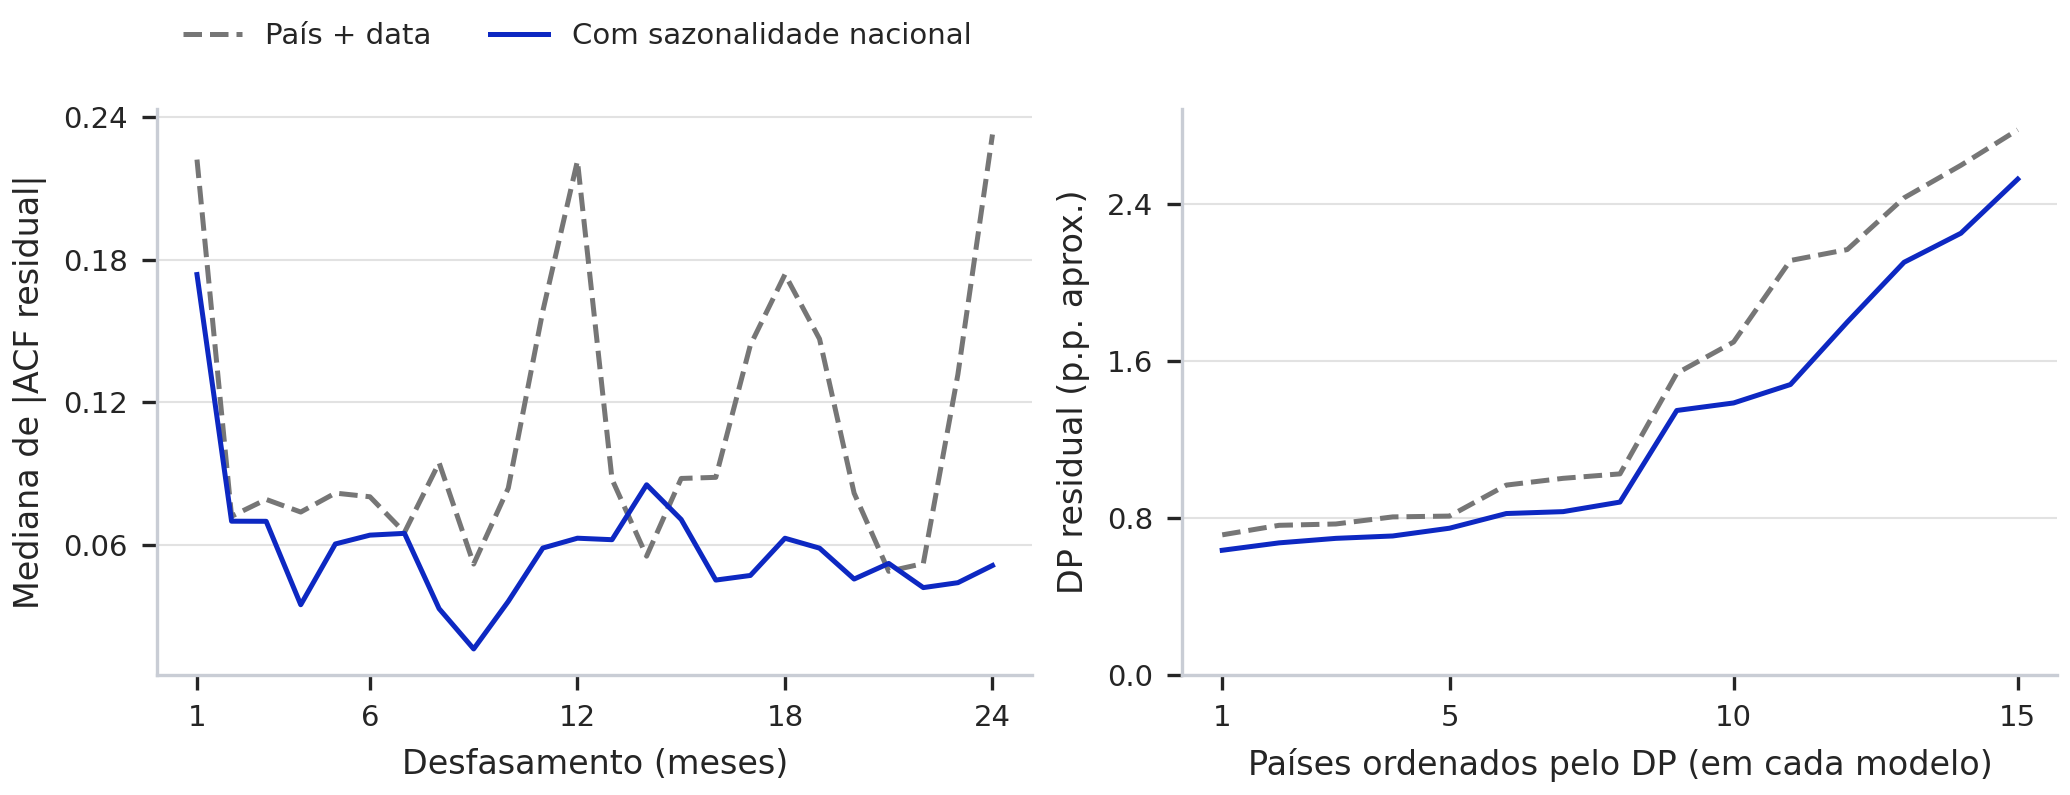

In [7]:
display(resumo_residuos.round(3))
contagens = residuos_pais.groupby("modelo").agg(
    paises_p_lb12_menor_005=("p_lb12", lambda s: int((s < .05).sum())),
    paises_p_lb24_menor_005=("p_lb24", lambda s: int((s < .05).sum())),
)
display(contagens)
display(residuos_pais.query("modelo == 'FE pais data sazonal'")
        [["pais_iso3", "dp", "acf1", "acf12", "p_lb12", "p_lb24"]].round(4))
display(Image(filename=str(graficos / "04_residuos.png"), width=850))

**Figura 4.2.** Mediana de |ACF| e dispersão residual, com e sem sazonalidade nacional. Fonte: resíduos dos modelos. À direita, os países são ordenados separadamente por desvio padrão; a posição não identifica o mesmo país nos dois modelos.

Os desvios padrão residuais do FE final vão de 0,635 a 2,528, uma razão próxima de quatro. A heterogeneidade sustenta a inferência robusta. A sazonalidade nacional reduz o número de países sinalizados pelo Ljung–Box a 12 meses de 14 para 9, mas 13 continuam sinalizados a 24 meses. Os valores-p são diagnósticos individuais, não ajustados por multiplicidade nem testes exatos depois de estimar tantos efeitos.

Os erros agrupados permitem heteroscedasticidade e dependência dentro do país. Com 15 grupos, os intervalos t(14) continuam aproximados; não resolvem a dependência entre países. A mediana das correlações residuais no FE final é −0,095 e a mediana dos valores absolutos 0,212. A restrição transversal imposta pelos efeitos de data pode induzir correlações negativas. Por isso, nem uma mediana perto de zero nem os efeitos de data provam independência transversal.

## 7. Tendências e estacionariedade

A resposta usa a variação logarítmica mensal do IPC, em vez de índices de preços em nível. O ADF testa a hipótese de raiz unitária; o KPSS testa estacionariedade. Não rejeitar uma hipótese não a prova.

Para a resposta mensal, os testes incluem constante. Para as variáveis económicas, usa-se uma observação por ano e constante/tendência: repetir valores anuais nos meses não aumenta a informação para testar raízes unitárias.

In [8]:
estacionariedade = pd.read_csv(tabelas / "05_estacionariedade.csv")
display(estacionariedade.groupby("variavel").agg(
    n_por_pais=("n", "first"),
    adf_rejeita=("p_adf", lambda s: int((s < .05).sum())),
    kpss_rejeita=("p_kpss", lambda s: int((s < .05).sum())),
))
display(estacionariedade.query("variavel == 'peso_agricola_pct_ano_anterior'")
        [["pais_iso3", "n", "p_adf", "p_kpss", "p_kpss_limite", "lags_adf", "lags_kpss"]].round(4))

,n_por_pais,adf_rejeita,kpss_rejeita
variavel,,,
inflacao_alimentar_log_pct,311,15,2
ln_pib_pc_ppc_ano_anterior,26,3,9
peso_agricola_pct_ano_anterior,26,5,8


,pais_iso3,n,p_adf,p_kpss,p_kpss_limite,lags_adf,lags_kpss
1,BDI,26,0.0356,0.0196,=,0,2
4,BEN,26,0.8812,0.1000,>,0,2
7,BFA,26,0.0003,0.1000,>,0,1
10,BRA,26,0.6819,0.0433,=,0,3
13,ESP,26,0.1964,0.0334,=,3,3
16,HND,26,0.0331,0.1000,>,0,0
19,JPN,26,0.0935,0.0963,=,1,2
22,MEX,26,0.4659,0.0179,=,0,3
25,MLI,26,0.0095,0.1000,>,3,3
28,NER,26,0.9937,0.0345,=,1,3


O ADF rejeita raiz unitária da resposta nos 15 países; o KPSS rejeita estacionariedade em torno de uma constante em 2. Isso permite trabalhar com uma taxa mensal, mas não afasta mudanças de média ou quebras.

Na agricultura, o ADF rejeita em 5 países e o KPSS em 8; no log PIB, em 3 e 9, respetivamente. Há só 26 observações anuais por país e potência limitada. Os avisos dos limites tabulados do KPSS ficam registados no CSV. Estes testes não justificam declarar todas as covariáveis estacionárias. O log PIB não integra o modelo principal; para a agricultura, mantém-se prudência e verifica-se uma extensão com tendências nacionais.

## 8. Sensibilidade: tendências, extremos e calendário do clima

As tendências nacionais acrescentam 14 contrastes lineares; a tendência comum já está absorvida nas datas. O cenário com limites 1%/99% usa uma cópia da resposta e mantém todos os registos.

A variante desfasada substitui a temperatura corrente pela do mês anterior e recalcula a interação. Não acrescenta um quinto termo substantivo. O défice permanece contemporâneo e a agricultura corresponde ao ano anterior ao mês da resposta. Perde-se o primeiro mês de cada país, pelo que o contemporâneo é reestimado na mesma amostra de 4 650 observações.

| Termo | Corrente amostra lag | Lag 1 amostra lag |
|---|---|---|
| Anomalia térmica | -0,041 [-0,095; 0,013] | 0,109 [0,030; 0,189] |
| Défice hídrico | -0,022 [-0,083; 0,038] | -0,051 [-0,115; 0,013] |
| Peso agrícola centrado | -0,029 [-0,061; 0,004] | -0,030 [-0,066; 0,006] |
| Anomalia × peso agrícola | 0,002 [-0,004; 0,008] | 0,007 [0,002; 0,013] |
| Observações | 4650 | 4650 |
| R² do modelo | 0,3807 | 0,3822 |

| Termo | FE com tendencias nacionais | FE limites 1 e 99 |
|---|---|---|
| Anomalia térmica | -0,040 [-0,107; 0,028] | -0,043 [-0,095; 0,008] |
| Défice hídrico | -0,020 [-0,079; 0,040] | -0,020 [-0,076; 0,036] |
| Peso agrícola centrado | -0,021 [-0,059; 0,017] | -0,029 [-0,064; 0,005] |
| Anomalia × peso agrícola | 0,003 [-0,004; 0,009] | 0,002 [-0,004; 0,008] |
| Observações | 4665 | 4665 |
| R² do modelo | 0,3832 | 0,3855 |

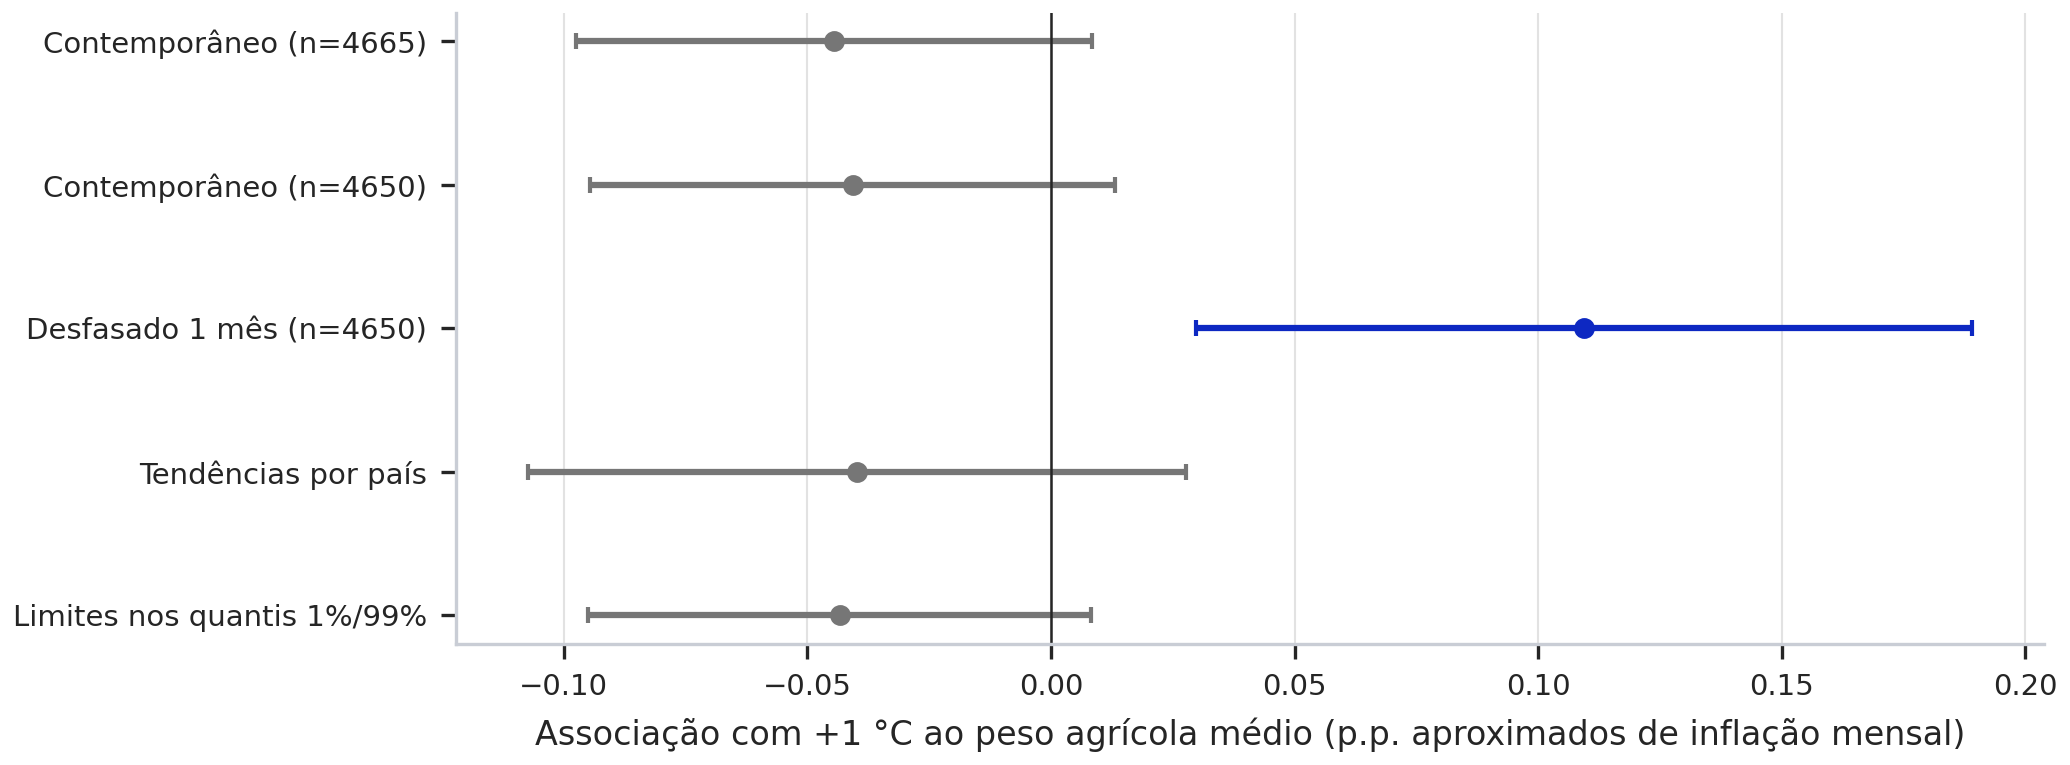

In [9]:
lag = pd.read_csv(tabelas / "04_sensibilidade_lag.csv")
robustez = pd.read_csv(tabelas / "08_robustez.csv")
display(Markdown(tabela_modelos(lag, ["Corrente amostra lag", "Lag 1 amostra lag"])))
display(Markdown(tabela_modelos(robustez, ["FE com tendencias nacionais", "FE limites 1 e 99"])))
display(Image(filename=str(graficos / "05_sensibilidade.png"), width=850))

**Figura 4.3.** Coeficiente térmico ao peso agrícola médio, com IC 95% agrupados por país. Fonte: modelos de sensibilidade. As duas estimativas centrais identificam explicitamente a amostra comparável.

Com tendências nacionais, a estimativa contemporânea é −0,040 [−0,107; 0,028]; com limites nos quantis, é −0,043 [−0,095; 0,008]. O resultado contemporâneo não depende apenas dos maiores extremos ou de tendências lineares nacionais.

No lag de um mês, a estimativa muda para +0,109 [0,030; 0,189], e a interação para +0,0074 [0,0020; 0,0128]. O resultado merece discussão, mas não é uma identificação causal. A substituição não estima os efeitos corrente e desfasado em simultâneo nem um efeito acumulado; persistência das exposições e dinâmica omitida podem influenciar ambos. Não se escolhe a variante principal depois de observar qual produz significância.

[Kotz et al. (2024)](https://doi.org/10.1038/s43247-023-01173-x) motivam estudar efeitos distribuídos no tempo. As diferenças de amostra e especificação impedem usar esse artigo como validação das estimativas deste painel.

## 8.1 Auditoria da inferência e influência dos países

Três verificações complementam a auditoria do código:

- A regressão final foi recalculada por residualização dos quatro regressores e da resposta face aos controlos (Frisch–Waugh–Lovell), confirmando os coeficientes. O número de condição após residualizar e padronizar os quatro regressores avalia a colinearidade que importa para os seus declives.
- A inferência foi recalculada com [Driscoll–Kraay](https://www.statsmodels.org/stable/generated/statsmodels.stats.sandwich_covariance.cov_nw_groupsum.html), permitindo dependência transversal e temporal numa aproximação para T longo. São apresentados kernel de Bartlett, larguras de 12 e 24 meses, correção N/(N−K) e referência t(T−1) aproximada. A largura não é escolhida pelo menor valor-p.
- Cada país foi retirado uma vez, mantendo fixo o centro original da agricultura e reestimando os controlos. As 15 estimativas de cada calendário são guardadas; nenhuma exclusão é aplicada à análise principal.

Os erros agrupados com 15 países e os de Driscoll–Kraay têm aproximações diferentes; nenhum garante inferência exata. O método adicional fica como sensibilidade, não como substituição automática do método principal. Os testes unitários reproduzem entradas inválidas e falhas de execução; uma execução sem erros é apenas uma parte da validação.

In [10]:
display(inferencia_dk.query("termo == 'calor'")
        [["modelo", "largura", "coeficiente", "ep", "ic95_inf", "ic95_sup", "p_aproximado"]].round(4))
display(influencia.query("termo == 'calor'").groupby("modelo").coeficiente.agg(["min", "max"]).round(4))
display(pd.DataFrame([{
    "Erro máximo FWL": auditoria["erro_maximo_fwl"],
    "Condição dos quatro regressores após controlos": auditoria["condicao_regressores_apos_controlos"],
    "Verificação DK com lag zero": auditoria["dk_lag_zero_confere"],
}]))

,modelo,largura,coeficiente,ep,ic95_inf,ic95_sup,p_aproximado
0,Contemporaneo,12,-0.0445,0.0469,-0.1368,0.0479,0.3439
4,Contemporaneo,24,-0.0445,0.0445,-0.1321,0.0431,0.3185
8,Lag 1,12,0.1094,0.0461,0.0187,0.2002,0.0183
12,Lag 1,24,0.1094,0.0461,0.0187,0.2002,0.0183


,min,max
modelo,,
Contemporaneo,-0.0565,-0.0165
Lag 1,0.0879,0.1280


,Erro máximo FWL,Condição dos quatro regressores após controlos,Verificação DK com lag zero
0,3.580036e-15,1.493476,True


**Tabela 4.4.** Inferência térmica por Driscoll–Kraay e amplitude das estimativas após retirar um país de cada vez. As tabelas completas incluem todos os regressores.

A temperatura contemporânea mantém o sinal negativo em todas as exclusões, com valores de −0,056 a −0,016. A retirada do Níger altera consideravelmente a magnitude, sem mudar o sinal. A estimativa desfasada permanece positiva, entre 0,088 e 0,128. São verificações de estabilidade, não demonstrações de causalidade ou representatividade.

Com Driscoll–Kraay a 12 meses, o IC contemporâneo é [−0,137; 0,048], p aproximado 0,344; para a temperatura desfasada é [0,019; 0,200], p aproximado 0,018. A largura de 24 meses dá conclusões qualitativas semelhantes. O resultado contemporâneo continua incerto; a associação desfasada continua positiva nas verificações consideradas. A dependência, as variáveis omitidas e o número limitado de países permanecem limitações.

## 9. Resposta ao problema

A inflação alimentar muda sobretudo dentro dos países e apresenta sazonalidade nacional e movimentos comuns. O FE com país, data e sazonalidade é adequado para descrever a associação contemporânea porque controla esses padrões e permite correlação entre heterogeneidade persistente e covariáveis.

O coeficiente térmico contemporâneo, ao peso agrícola médio, deixa de excluir zero depois de controlar a sazonalidade nacional. O défice e a interação contemporânea também têm intervalos que incluem zero. A variante desfasada apresenta associações positivas. Estes resultados mostram que a definição temporal da exposição importa; não sustentam a afirmação de que o clima não afeta preços, nem uma conclusão causal de sinal único.

Permanecem variáveis omitidas (câmbios, comércio, energia, políticas, conflitos), diferenças de cabazes, erros de medição climática e uma seleção intencional de apenas 15 países. Médias nacionais de clima não representam necessariamente as áreas agrícolas. A dependência residual e a fraca variação anual da agricultura limitam a inferência.

## 10. Verificação e ficheiros

`relatorio/parte1.md` apresenta uma leitura autónoma da Parte 1; os CSV guardam os valores sem arredondamento de apresentação. As cinco figuras compactas estão disponíveis em PNG, SVG e PDF. As entradas originais não são alteradas.

O apoio de IA conhecido encontra-se em `docs/uso_ia.md`. O grupo deve confirmar o registo na UC e completar a declaração com usos anteriores. A Parte 2 e o relatório final conjunto não estão incluídos neste notebook.

In [11]:
assert metadados["n"] == 4665
assert lag.n.eq(4650).all()
assert coefs[["coeficiente", "ep_cluster", "ic95_inf", "ic95_sup"]].notna().all().all()
assert coefs.ic95_inf.le(coefs.coeficiente).all()
assert coefs.ic95_sup.ge(coefs.coeficiente).all()
print("Verificações numéricas concluídas. Síntese atualizada em relatorio/parte1.md.")

Verificações numéricas concluídas. Síntese atualizada em relatorio/parte1.md.
